In [1]:
import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print(
        "GPU Memory:",
        round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2),
        "GB"
    )
else:
    print("GPU not available. Please enable a GPU runtime.")

PyTorch version: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4
GPU Memory: 14.56 GB


In [2]:
!pip install -q transformers datasets accelerate peft

In [3]:
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM

MODEL_NAME = "Qwen/Qwen2.5-1.5B-Instruct"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

model = AutoModelForCausalLM.from_pretrained(
    MODEL_NAME,
    torch_dtype="auto",
    device_map="auto"
)

model.eval()

print("Model loaded successfully!")
print("Device:", model.device)

config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 3.09GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

Model loaded successfully!
Device: cuda:0


In [4]:
messages = [
    {
        "role": "user",
        "content": "Explain the difference between GET and POST requests in Python APIs."
    }
]

inputs = tokenizer.apply_chat_template(
    messages,
    tokenize=True,
    add_generation_prompt=True,
    return_tensors="pt"
).to(model.device)

with torch.no_grad():
    outputs = model.generate(
        **inputs,
        max_new_tokens=150,
        do_sample=False
    )

answer = tokenizer.decode(
    outputs[0][inputs["input_ids"].shape[-1]:],
    skip_special_tokens=True
)

print(answer)

In Python APIs, `GET` and `POST` are two common HTTP methods used to send data to a server.

1. **GET Method**: This method is used for retrieving data from a web application or API. When using the GET method, all parameters passed with the request are sent as part of the URL query string. For example, if you were making an API call to retrieve user information, you might use something like this:

   ```
   https://api.example.com/users?username=example_user
   ```

   In this case, the username parameter would be included in the URL itself rather than being sent as part of the body of the request.

2. **POST Method**: This method is used for submitting data to a web


In [5]:
import json
import random
from pathlib import Path
from sklearn.model_selection import train_test_split

data = [
    # Python
    {"instruction": "What is a Python list?", "input": "",
     "output": "A list is an ordered, mutable collection that can store multiple items, including duplicate values."},
    {"instruction": "What is a Python tuple?", "input": "",
     "output": "A tuple is an ordered collection that cannot be modified after it is created."},
    {"instruction": "What is a Python dictionary?", "input": "",
     "output": "A dictionary stores key-value pairs. Keys must be unique and hashable."},
    {"instruction": "What is the difference between == and is in Python?", "input": "",
     "output": "The == operator compares values, while is checks whether two references point to the same object."},
    {"instruction": "What is a Python function?", "input": "",
     "output": "A function is a reusable block of code defined with def that can accept arguments and return a result."},
    {"instruction": "What is a Python decorator?", "input": "",
     "output": "A decorator wraps a function or class to extend or modify its behavior without directly changing its source code."},
    {"instruction": "What is exception handling in Python?", "input": "",
     "output": "Exception handling uses try and except blocks to handle runtime errors. A finally block can run cleanup code."},
    {"instruction": "What is a Python class?", "input": "",
     "output": "A class defines a structure for creating objects with attributes and methods."},
    {"instruction": "What is inheritance in Python?", "input": "",
     "output": "Inheritance allows a class to derive attributes and methods from another class."},
    {"instruction": "What is a Python generator?", "input": "",
     "output": "A generator produces values lazily, commonly using yield, instead of creating all results at once."},

    # APIs and HTTP
    {"instruction": "What is a REST API?", "input": "",
     "output": "A REST API exposes resources through HTTP and commonly uses methods such as GET, POST, PUT, PATCH, and DELETE."},
    {"instruction": "What is the difference between GET and POST?", "input": "",
     "output": "GET requests retrieve data. POST requests submit data for processing or resource creation."},
    {"instruction": "What does HTTP status code 200 mean?", "input": "",
     "output": "HTTP 200 OK indicates that the request succeeded."},
    {"instruction": "What does HTTP status code 404 mean?", "input": "",
     "output": "HTTP 404 Not Found indicates that the requested resource could not be found."},
    {"instruction": "What does HTTP status code 500 mean?", "input": "",
     "output": "HTTP 500 Internal Server Error indicates that the server encountered an unexpected condition."},
    {"instruction": "What is JSON?", "input": "",
     "output": "JSON is a text-based data format that represents structured data using objects, arrays, strings, numbers, booleans, and null."},
    {"instruction": "What is an API endpoint?", "input": "",
     "output": "An API endpoint is a specific URL and HTTP method through which a client accesses an API operation."},
    {"instruction": "What is FastAPI?", "input": "",
     "output": "FastAPI is a Python framework for building APIs with type hints, request validation, and automatic OpenAPI documentation."},
    {"instruction": "What is request validation?", "input": "",
     "output": "Request validation checks incoming data against expected types and rules before processing it."},
    {"instruction": "What is the difference between PUT and PATCH?", "input": "",
     "output": "PUT generally replaces a resource representation, while PATCH applies partial modifications to a resource."},

    # SQL and databases
    {"instruction": "What is SQL?", "input": "",
     "output": "SQL is a language used to query and manage data in relational database systems."},
    {"instruction": "What is a primary key?", "input": "",
     "output": "A primary key uniquely identifies each row in a table and cannot contain NULL values."},
    {"instruction": "What is a foreign key?", "input": "",
     "output": "A foreign key references a candidate key, usually a primary key, in the same or another table to enforce referential integrity."},
    {"instruction": "What is the difference between WHERE and HAVING?", "input": "",
     "output": "WHERE filters rows before grouping. HAVING filters groups after GROUP BY."},
    {"instruction": "What does GROUP BY do in SQL?", "input": "",
     "output": "GROUP BY groups rows with matching values so aggregate functions can calculate results for each group."},
    {"instruction": "What is an SQL JOIN?", "input": "",
     "output": "A JOIN combines rows from two or more tables using a related column or join condition."},
    {"instruction": "What is an INNER JOIN?", "input": "",
     "output": "An INNER JOIN returns rows that satisfy the join condition in both tables."},
    {"instruction": "What is a database index?", "input": "",
     "output": "An index can speed up data retrieval, but it requires storage and can add overhead to data modifications."},
    {"instruction": "What is database normalization?", "input": "",
     "output": "Normalization organizes relational data to reduce unnecessary duplication and improve data integrity."},
    {"instruction": "What is a SQL transaction?", "input": "",
     "output": "A transaction is a group of database operations treated as one logical unit, commonly governed by ACID properties."},

    # Machine learning and software
    {"instruction": "What is machine learning?", "input": "",
     "output": "Machine learning is a field of AI in which algorithms learn patterns from data to make predictions or decisions."},
    {"instruction": "What is supervised learning?", "input": "",
     "output": "Supervised learning trains a model using examples containing input features and target labels or values."},
    {"instruction": "What is overfitting?", "input": "",
     "output": "Overfitting occurs when a model learns training data too closely and performs poorly on unseen data."},
    {"instruction": "What is a train-test split?", "input": "",
     "output": "A train-test split separates data for model fitting from data reserved to evaluate performance on unseen examples."},
    {"instruction": "What is precision in machine learning?", "input": "",
     "output": "Precision is the proportion of predicted positive cases that are actually positive: TP divided by TP plus FP."},
    {"instruction": "What is recall in machine learning?", "input": "",
     "output": "Recall is the proportion of actual positive cases correctly identified: TP divided by TP plus FN."},
    {"instruction": "What is Git?", "input": "",
     "output": "Git is a distributed version control system that tracks changes to files and supports collaboration."},
    {"instruction": "What is Docker?", "input": "",
     "output": "Docker packages an application and its dependencies into containers to help it run consistently across environments."},
    {"instruction": "What is unit testing?", "input": "",
     "output": "Unit testing checks individual functions or components in isolation to verify their expected behavior."},
    {"instruction": "What is the difference between authentication and authorization?", "input": "",
     "output": "Authentication verifies who a user is. Authorization determines what that user is allowed to access or do."}
]

# Validate records
seen = set()
clean_data = []

for item in data:
    question = item["instruction"].strip()
    answer = item["output"].strip()

    if not question or not answer:
        continue

    key = question.casefold()
    if key in seen:
        continue

    seen.add(key)
    clean_data.append({
        "instruction": question,
        "input": item["input"].strip(),
        "output": answer
    })

# Split: 70% train, 15% validation, 15% test
train_data, remaining = train_test_split(
    clean_data, test_size=0.30, random_state=42
)

val_data, test_data = train_test_split(
    remaining, test_size=0.50, random_state=42
)

# Save each dataset as JSONL
output_dir = Path("/content/llm_project")
output_dir.mkdir(parents=True, exist_ok=True)

for name, records in [
    ("train.jsonl", train_data),
    ("validation.jsonl", val_data),
    ("test.jsonl", test_data)
]:
    with open(output_dir / name, "w", encoding="utf-8") as f:
        for record in records:
            f.write(json.dumps(record, ensure_ascii=False) + "\n")

print("Total clean examples:", len(clean_data))
print("Training examples:", len(train_data))
print("Validation examples:", len(val_data))
print("Test examples:", len(test_data))
print("Files saved in:", output_dir)

Total clean examples: 40
Training examples: 28
Validation examples: 6
Test examples: 6
Files saved in: /content/llm_project


In [6]:
baseline_questions = [
    "How do you reverse a list in Python?",
    "What is the difference between a list and a set?",
    "What are *args and **kwargs in Python?",
    "What is a shallow copy?",
    "What is a deep copy?",
    "How does a Python virtual environment help?",
    "How do you handle a missing key in a dictionary?",
    "What is the difference between synchronous and asynchronous code?",
    "How do you send a GET request in Python?",
    "What is the purpose of Pydantic in FastAPI?",
    "How should an API handle invalid input?",
    "What is the difference between HTTP 401 and 403?",
    "What is the purpose of an API response status code?",
    "How can API response time be measured?",
    "How do you count rows in SQL?",
    "What is the difference between DELETE and DROP in SQL?",
    "What is a SQL aggregate function?",
    "What is a confusion matrix?",
    "What is the difference between classification and regression?",
    "How can you investigate a Python ModuleNotFoundError?"
]

print("Number of fixed baseline questions:", len(baseline_questions))

Number of fixed baseline questions: 20


In [7]:
baseline_results = []

for i, question in enumerate(baseline_questions, start=1):
    messages = [
        {
            "role": "user",
            "content": question
        }
    ]

    inputs = tokenizer.apply_chat_template(
        messages,
        tokenize=True,
        add_generation_prompt=True,
        return_tensors="pt"
    ).to(model.device)

    with torch.no_grad():
        outputs = model.generate(
            **inputs,
            max_new_tokens=180,
            do_sample=False
        )

    answer = tokenizer.decode(
        outputs[0][inputs["input_ids"].shape[-1]:],
        skip_special_tokens=True
    ).strip()

    baseline_results.append({
        "id": i,
        "question": question,
        "baseline_answer": answer
    })

    print(f"\n{i}. {question}\n{answer}")

with open(
    "/content/llm_project/baseline_predictions.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        baseline_results,
        f,
        ensure_ascii=False,
        indent=2
    )

print("\nSaved baseline predictions.")


1. How do you reverse a list in Python?
In Python, reversing a list can be done using several methods:

1. Using the `reverse()` method:
```python
my_list = [1, 2, 3, 4]
my_list.reverse()
print(my_list)  # Output: [4, 3, 2, 1]
```

2. Using slicing with negative indices:
```python
my_list = [1, 2, 3, 4]
reversed_list = my_list[::-1]
print(reversed_list)  # Output: [4, 3, 2, 1]
```

3. Using the `list()` constructor and the `reversed()` function:
```python
my_list = [1, 2, 3, 4]
reversed_list = list(reversed(my_list))
print(reversed_list)  # Output: [4,

2. What is the difference between a list and a set?
A list and a set are both data structures used in programming to store collections of items, but they have some key differences:

1. Order: In a list, the order of elements matters. The first element has index 0, the second element has index 1, and so on. Lists can be modified after creation (e.g., adding or removing elements).

2. Uniqueness: A list allows duplicate values. If you cr

In [8]:
import shutil

zip_path = shutil.make_archive(
    "/content/day1_deliverables",
    "zip",
    "/content/llm_project"
)

print("Created:", zip_path)

Created: /content/day1_deliverables.zip


In [9]:
import json
from pathlib import Path

project_dir = Path("/content/llm_project")

for filename in [
    "train.jsonl",
    "validation.jsonl",
    "test.jsonl"
]:
    path = project_dir / filename

    if not path.exists():
        print(f"MISSING: {filename}")
        continue

    records = []
    errors = []

    with open(path, encoding="utf-8") as f:
        for line_no, line in enumerate(f, start=1):
            try:
                record = json.loads(line)

                if not record.get("instruction", "").strip():
                    errors.append(f"Line {line_no}: empty question")

                if not record.get("output", "").strip():
                    errors.append(f"Line {line_no}: empty answer")

                records.append(record)

            except json.JSONDecodeError:
                errors.append(f"Line {line_no}: invalid JSON")

    print(f"\n{filename}")
    print("Records:", len(records))
    print("Errors:", errors if errors else "None")


train.jsonl
Records: 28
Errors: None

validation.jsonl
Records: 6
Errors: None

test.jsonl
Records: 6
Errors: None


In [10]:
baseline_path = project_dir / "baseline_predictions.json"

if baseline_path.exists():
    with open(baseline_path, encoding="utf-8") as f:
        baseline = json.load(f)

    print("Baseline questions:", len(baseline))
    print("First question:", baseline[0]["question"])
    print("First answer:", baseline[0]["baseline_answer"])
else:
    print("Baseline predictions file is missing.")

Baseline questions: 20
First question: How do you reverse a list in Python?
First answer: In Python, reversing a list can be done using several methods:

1. Using the `reverse()` method:
```python
my_list = [1, 2, 3, 4]
my_list.reverse()
print(my_list)  # Output: [4, 3, 2, 1]
```

2. Using slicing with negative indices:
```python
my_list = [1, 2, 3, 4]
reversed_list = my_list[::-1]
print(reversed_list)  # Output: [4, 3, 2, 1]
```

3. Using the `list()` constructor and the `reversed()` function:
```python
my_list = [1, 2, 3, 4]
reversed_list = list(reversed(my_list))
print(reversed_list)  # Output: [4,


In [11]:
import json
import pandas as pd
from pathlib import Path

project_dir = Path("/content/llm_project")

with open(
    project_dir / "baseline_predictions.json",
    encoding="utf-8"
) as f:
    baseline = json.load(f)

evaluation_rows = []

for item in baseline:
    evaluation_rows.append({
        "id": item["id"],
        "question": item["question"],
        "baseline_answer": item["baseline_answer"],
        "correctness_1_to_5": "",
        "relevance_1_to_5": "",
        "completeness_1_to_5": "",
        "clarity_1_to_5": "",
        "issues_observed": ""
    })

df = pd.DataFrame(evaluation_rows)

output_file = project_dir / "baseline_evaluation.csv"
df.to_csv(output_file, index=False)

print("Evaluation sheet created:", output_file)
print("Questions to evaluate:", len(df))
print(df[["id", "question"]].to_string(index=False))

Evaluation sheet created: /content/llm_project/baseline_evaluation.csv
Questions to evaluate: 20
 id                                                          question
  1                              How do you reverse a list in Python?
  2                  What is the difference between a list and a set?
  3                            What are *args and **kwargs in Python?
  4                                           What is a shallow copy?
  5                                              What is a deep copy?
  6                       How does a Python virtual environment help?
  7                  How do you handle a missing key in a dictionary?
  8 What is the difference between synchronous and asynchronous code?
  9                          How do you send a GET request in Python?
 10                       What is the purpose of Pydantic in FastAPI?
 11                           How should an API handle invalid input?
 12                  What is the difference between HTTP 401 an

day 2


In [12]:
from pathlib import Path
from transformers import AutoTokenizer
import json

MODEL_NAME = "Qwen/Qwen2.5-1.5B-Instruct"
DATA_DIR = Path("/content/llm_project")

required_files = [
    "train.jsonl",
    "validation.jsonl",
    "test.jsonl"
]

for filename in required_files:
    path = DATA_DIR / filename
    assert path.exists(), (
        f"Missing {filename}. Upload or restore your Day 1 dataset."
    )

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

print("Tokenizer loaded:", MODEL_NAME)
print("Vocabulary size:", len(tokenizer))
print("Chat template available:", tokenizer.chat_template is not None)

Tokenizer loaded: Qwen/Qwen2.5-1.5B-Instruct
Vocabulary size: 151665
Chat template available: True


In [13]:
import json
from pathlib import Path
from datasets import Dataset

DATA_DIR = Path("/content/llm_project")

def load_jsonl(filename):
    records = []
    with open(DATA_DIR / filename, "r", encoding="utf-8") as f:
        for line in f:
            records.append(json.loads(line))
    return records

train_records = load_jsonl("train.jsonl")
validation_records = load_jsonl("validation.jsonl")

def format_example(example):
    question = example["instruction"].strip()
    extra_input = example.get("input", "").strip()

    if extra_input:
        question += "\n\nAdditional context:\n" + extra_input

    messages = [
        {"role": "user", "content": question},
        {"role": "assistant", "content": example["output"].strip()}
    ]

    return {
        "text": tokenizer.apply_chat_template(
            messages,
            tokenize=False,
            add_generation_prompt=False
        )
    }

train_dataset = Dataset.from_list(train_records).map(
    format_example,
    remove_columns=Dataset.from_list(train_records).column_names
)

validation_dataset = Dataset.from_list(validation_records).map(
    format_example,
    remove_columns=Dataset.from_list(validation_records).column_names
)

print("Training examples:", len(train_dataset))
print("Validation examples:", len(validation_dataset))
print("\nFormatted example:\n")
print(train_dataset[0]["text"])

Map:   0%|          | 0/28 [00:00<?, ? examples/s]

Map:   0%|          | 0/6 [00:00<?, ? examples/s]

Training examples: 28
Validation examples: 6

Formatted example:

<|im_start|>system
You are Qwen, created by Alibaba Cloud. You are a helpful assistant.<|im_end|>
<|im_start|>user
What does HTTP status code 404 mean?<|im_end|>
<|im_start|>assistant
HTTP 404 Not Found indicates that the requested resource could not be found.<|im_end|>



In [14]:
sample = train_dataset[0]["text"]

tokens = tokenizer(
    sample,
    truncation=True,
    max_length=512
)

print("Token count:", len(tokens["input_ids"]))
print("First 20 token IDs:", tokens["input_ids"][:20])
print("Tokenizer test passed:", len(tokens["input_ids"]) > 0)

Token count: 59
First 20 token IDs: [151644, 8948, 198, 2610, 525, 1207, 16948, 11, 3465, 553, 54364, 14817, 13, 1446, 525, 264, 10950, 17847, 13, 151645]
Tokenizer test passed: True


In [15]:
!pip install -q trl
!pip install --upgrade torchao

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 945.8/945.8 kB 39.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.4/3.4 MB 106.9 MB/s eta 0:00:00
  Attempting uninstall: torchao
    Found existing installation: torchao 0.10.0
    Uninstalling torchao-0.10.0:
      Successfully uninstalled torchao-0.10.0


In [16]:
import sys
import torch
from transformers import (
    AutoModelForCausalLM,
    TrainingArguments,
    Trainer,
    DataCollatorForLanguageModeling
)
from peft import LoraConfig, get_peft_model

MODEL_NAME = "Qwen/Qwen2.5-1.5B-Instruct"

model = AutoModelForCausalLM.from_pretrained(
    MODEL_NAME,
    torch_dtype=torch.float16,
    device_map="auto"
)

model.config.use_cache = False
model.gradient_checkpointing_enable()

lora_config = LoraConfig(
    r=8,
    lora_alpha=16,
    lora_dropout=0.05,
    target_modules=[
        "q_proj",
        "k_proj",
        "v_proj",
        "o_proj"
    ],
    task_type="CAUSAL_LM"
)

# Temporarily mask torchao to bypass the PEFT version compatibility check
try:
    import peft.import_utils
    peft.import_utils.is_torchao_available = lambda: False
except AttributeError:
    pass

model = get_peft_model(model, lora_config)
model.print_trainable_parameters()

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

trainable params: 2,179,072 || all params: 1,545,893,376 || trainable%: 0.1410


In [17]:
MAX_LENGTH = 512

def tokenize_example(example):
    return tokenizer(
        example["text"],
        truncation=True,
        max_length=MAX_LENGTH,
        padding=False
    )

tokenized_train = train_dataset.map(
    tokenize_example,
    remove_columns=["text"]
)

tokenized_validation = validation_dataset.map(
    tokenize_example,
    remove_columns=["text"]
)

print("Tokenized train:", len(tokenized_train))
print("Tokenized validation:", len(tokenized_validation))

Map:   0%|          | 0/28 [00:00<?, ? examples/s]

Map:   0%|          | 0/6 [00:00<?, ? examples/s]

Tokenized train: 28
Tokenized validation: 6


In [18]:
from pathlib import Path

pilot_dir = "/content/llm_project/pilot_adapter"

training_args = TrainingArguments(
    output_dir="/content/llm_project/pilot_checkpoints",
    per_device_train_batch_size=1,
    per_device_eval_batch_size=1,
    gradient_accumulation_steps=2,
    learning_rate=2e-4,
    num_train_epochs=1,
    max_steps=5,
    logging_steps=1,
    eval_strategy="steps",
    eval_steps=5,
    save_strategy="no",
    fp16=True,
    gradient_checkpointing=True,
    report_to="none",
    optim="adamw_torch"
)

data_collator = DataCollatorForLanguageModeling(
    tokenizer=tokenizer,
    mlm=False
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=tokenized_train,
    eval_dataset=tokenized_validation,
    data_collator=data_collator
)

torch.cuda.reset_peak_memory_stats()

train_result = trainer.train()

print("Training loss:", train_result.training_loss)
print(
    "Peak GPU memory (GB):",
    round(torch.cuda.max_memory_allocated() / 1024**3, 2)
)

Path(pilot_dir).mkdir(parents=True, exist_ok=True)
model.save_pretrained(pilot_dir)
tokenizer.save_pretrained(pilot_dir)

print("Pilot adapter saved:", pilot_dir)

Step,Training Loss,Validation Loss
5,2.655149,2.711386


Training loss: 3.3868446826934813
Peak GPU memory (GB): 3.03
Pilot adapter saved: /content/llm_project/pilot_adapter


In [19]:
from transformers import TrainingArguments, Trainer
from transformers.trainer_callback import EarlyStoppingCallback
from transformers import DataCollatorForLanguageModeling
import torch
import os

full_output_dir = "/content/llm_project/full_training"

# Enable cache only for inference, not training
model.config.use_cache = False

full_args = TrainingArguments(
    output_dir=full_output_dir,
    num_train_epochs=3,
    per_device_train_batch_size=1,
    per_device_eval_batch_size=1,
    gradient_accumulation_steps=2,
    learning_rate=2e-4,
    weight_decay=0.01,
    warmup_steps=1,
    logging_steps=1,
    eval_strategy="epoch",
    save_strategy="epoch",
    save_total_limit=2,
    load_best_model_at_end=True,
    metric_for_best_model="eval_loss",
    greater_is_better=False,
    fp16=True,
    gradient_checkpointing=True,
    report_to="none",
    optim="adamw_torch",
    seed=42
)

collator = DataCollatorForLanguageModeling(
    tokenizer=tokenizer,
    mlm=False
)

trainer = Trainer(
    model=model,
    args=full_args,
    train_dataset=tokenized_train,
    eval_dataset=tokenized_validation,
    data_collator=collator
)

torch.cuda.reset_peak_memory_stats()

result = trainer.train()

print("Final training loss:", result.training_loss)
print(
    "Peak GPU memory (GB):",
    round(torch.cuda.max_memory_allocated() / 1024**3, 2)
)

print("Evaluation:", trainer.evaluate())

Epoch,Training Loss,Validation Loss
1,1.118145,1.366079
2,0.805851,0.897171
3,0.727499,0.797663


Final training loss: 1.1349444219044276
Peak GPU memory (GB): 3.04


Training Loss,Validation Loss,Epoch
0.727499,0.797663,3


Evaluation: {'eval_loss': 0.797663152217865}


In [20]:
final_adapter_dir = "/content/llm_project/final_adapter"

trainer.model.save_pretrained(final_adapter_dir)
tokenizer.save_pretrained(final_adapter_dir)

print("Final adapter saved:", final_adapter_dir)
print("Saved files:", os.listdir(final_adapter_dir))

Final adapter saved: /content/llm_project/final_adapter
Saved files: ['tokenizer_config.json', 'adapter_model.safetensors', 'tokenizer.json', 'README.md', 'chat_template.jinja', 'adapter_config.json']


In [21]:
import pandas as pd

logs = pd.DataFrame(trainer.state.log_history)
logs.to_csv(
    "/content/llm_project/training_logs.csv",
    index=False
)

print("Training logs saved.")
display(logs.tail(10))

Training logs saved.


,loss,grad_norm,learning_rate,epoch,step,eval_loss,eval_runtime,eval_samples_per_second,eval_steps_per_second,train_runtime,train_samples_per_second,train_steps_per_second,total_flos,train_loss
37,0.622772,1.128641,0.000039,2.571429,36,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
38,0.482270,1.212250,0.000034,2.642857,37,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
39,0.764937,1.118028,0.000029,2.714286,38,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
40,0.647874,1.432182,0.000024,2.785714,39,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
41,0.702615,1.241333,0.000020,2.857143,40,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
42,0.377184,1.398572,0.000015,2.928571,41,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
43,0.727499,1.013189,0.000010,3.000000,42,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
44,NaN,NaN,NaN,3.000000,42,0.797663,0.5035,11.917,11.917,NaN,NaN,NaN,NaN,NaN
45,NaN,NaN,NaN,3.000000,42,NaN,NaN,NaN,NaN,57.8479,1.452,0.726,3.643030e+13,1.134944
46,NaN,NaN,NaN,3.000000,42,0.797663,0.5008,11.981,11.981,NaN,NaN,NaN,NaN,NaN


In [22]:
from pathlib import Path
import json
import pandas as pd

PROJECT_DIR = Path("/content/llm_project")
ADAPTER_DIR = PROJECT_DIR / "final_adapter"
LOG_FILE = PROJECT_DIR / "training_logs.csv"

print("Adapter directory exists:", ADAPTER_DIR.exists())

if ADAPTER_DIR.exists():
    for file in sorted(ADAPTER_DIR.iterdir()):
        print(file.name, "-", round(file.stat().st_size / 1024, 2), "KB")

    config_file = ADAPTER_DIR / "adapter_config.json"
    if config_file.exists():
        with open(config_file, encoding="utf-8") as f:
            config = json.load(f)

        print("\nBase model:", config.get("base_model_name_or_path"))
        print("LoRA rank:", config.get("r"))
        print("LoRA alpha:", config.get("lora_alpha"))

print("\nTraining logs exist:", LOG_FILE.exists())

if LOG_FILE.exists():
    logs = pd.read_csv(LOG_FILE)
    print("Log rows:", len(logs))
    print("Available columns:", logs.columns.tolist())

Adapter directory exists: True
README.md - 5.08 KB
adapter_config.json - 1.11 KB
adapter_model.safetensors - 8540.73 KB
chat_template.jinja - 2.45 KB
tokenizer.json - 11154.29 KB
tokenizer_config.json - 0.68 KB

Base model: Qwen/Qwen2.5-1.5B-Instruct
LoRA rank: 8
LoRA alpha: 16

Training logs exist: True
Log rows: 47
Available columns: ['loss', 'grad_norm', 'learning_rate', 'epoch', 'step', 'eval_loss', 'eval_runtime', 'eval_samples_per_second', 'eval_steps_per_second', 'train_runtime', 'train_samples_per_second', 'train_steps_per_second', 'total_flos', 'train_loss']


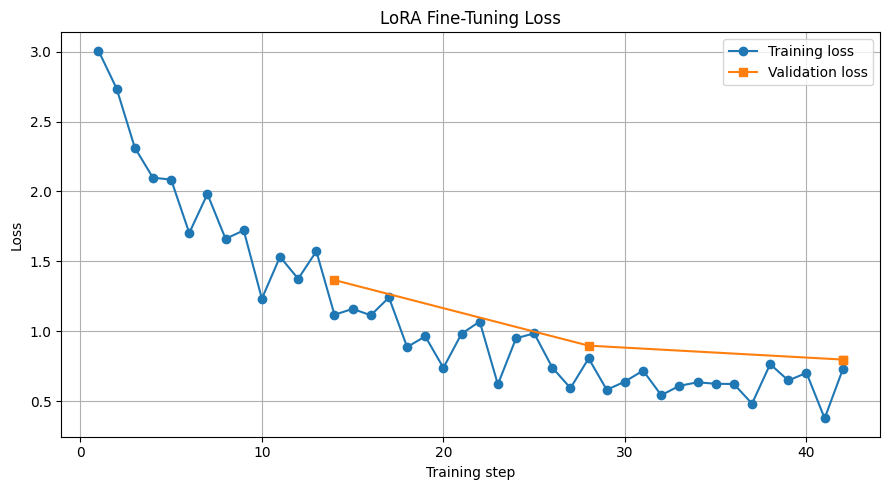

Loss graph saved.


In [23]:
import pandas as pd
import matplotlib.pyplot as plt

logs = pd.read_csv("/content/llm_project/training_logs.csv")

# Extract actual training and evaluation events
train_logs = logs[
    logs["loss"].notna() & logs["step"].notna()
]
eval_logs = logs[
    logs["eval_loss"].notna() & logs["step"].notna()
]

plt.figure(figsize=(9, 5))

if not train_logs.empty:
    plt.plot(
        train_logs["step"],
        train_logs["loss"],
        marker="o",
        label="Training loss"
    )

if not eval_logs.empty:
    plt.plot(
        eval_logs["step"],
        eval_logs["eval_loss"],
        marker="s",
        label="Validation loss"
    )

plt.xlabel("Training step")
plt.ylabel("Loss")
plt.title("LoRA Fine-Tuning Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig(
    "/content/llm_project/training_loss.png",
    dpi=150
)
plt.show()

print("Loss graph saved.")

In [24]:
from pathlib import Path
import json

project_dir = Path("/content/llm_project")
adapter_dir = project_dir / "final_adapter"

print("Adapter folder exists:", adapter_dir.exists())

if not adapter_dir.exists():
    print("ERROR: final_adapter folder not found!")
else:
    files = list(adapter_dir.iterdir())

    print("\nFiles inside final_adapter:")
    for file in files:
        print(f"- {file.name} ({file.stat().st_size:,} bytes)")

    config_path = adapter_dir / "adapter_config.json"

    if config_path.exists():
        with open(config_path, encoding="utf-8") as f:
            config = json.load(f)

        print("\nBase model:", config.get("base_model_name_or_path"))
        print("LoRA rank:", config.get("r"))
        print("LoRA alpha:", config.get("lora_alpha"))
        print("Target modules:", config.get("target_modules"))

    weights = [
        "adapter_model.safetensors",
        "adapter_model.bin"
    ]

    print(
        "\nAdapter weights found:",
        any((adapter_dir / name).exists() for name in weights)
    )

Adapter folder exists: True

Files inside final_adapter:
- tokenizer_config.json (694 bytes)
- adapter_model.safetensors (8,745,704 bytes)
- tokenizer.json (11,421,990 bytes)
- README.md (5,206 bytes)
- chat_template.jinja (2,507 bytes)
- adapter_config.json (1,132 bytes)

Base model: Qwen/Qwen2.5-1.5B-Instruct
LoRA rank: 8
LoRA alpha: 16
Target modules: ['k_proj', 'q_proj', 'v_proj', 'o_proj']

Adapter weights found: True


Training logs found: /content/llm_project/training_logs.csv
Total log records: 47
Available columns: ['loss', 'grad_norm', 'learning_rate', 'epoch', 'step', 'eval_loss', 'eval_runtime', 'eval_samples_per_second', 'eval_steps_per_second', 'train_runtime', 'train_samples_per_second', 'train_steps_per_second', 'total_flos', 'train_loss']

Last 10 log records:
    loss  grad_norm  learning_rate    epoch  step  eval_loss  eval_runtime  eval_samples_per_second  eval_steps_per_second  train_runtime  train_samples_per_second  train_steps_per_second   total_flos  train_loss
0.622772   1.128641       0.000039 2.571429    36        NaN           NaN                      NaN                    NaN            NaN                       NaN                     NaN          NaN         NaN
0.482270   1.212250       0.000034 2.642857    37        NaN           NaN                      NaN                    NaN            NaN                       NaN                     NaN          NaN         NaN
0.

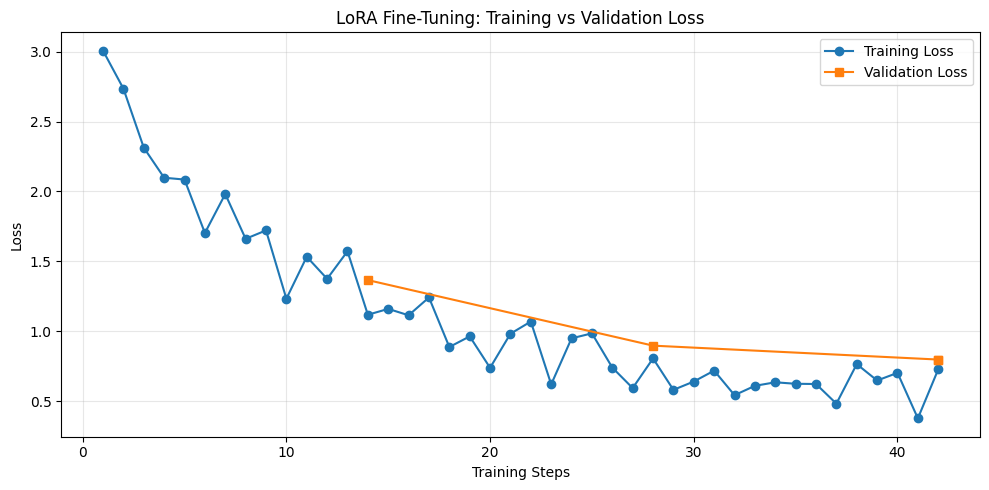


Loss graph saved to: /content/llm_project/training_loss.png


In [25]:

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

project_dir = Path("/content/llm_project")
logs_path = project_dir / "training_logs.csv"

# Check training logs
if not logs_path.exists():
    print("ERROR: training_logs.csv not found!")
else:
    logs = pd.read_csv(logs_path)

    print("Training logs found:", logs_path)
    print("Total log records:", len(logs))
    print("Available columns:", logs.columns.tolist())
    print("\nLast 10 log records:")
    print(logs.tail(10).to_string(index=False))

    # Plot training and evaluation loss
    if "step" in logs.columns:
        plt.figure(figsize=(10, 5))
        plotted = False

        if "loss" in logs.columns:
            train_logs = logs[
                logs["loss"].notna() & logs["step"].notna()
            ]
            if not train_logs.empty:
                plt.plot(
                    train_logs["step"],
                    train_logs["loss"],
                    marker="o",
                    label="Training Loss"
                )
                plotted = True

        if "eval_loss" in logs.columns:
            eval_logs = logs[
                logs["eval_loss"].notna() & logs["step"].notna()
            ]
            if not eval_logs.empty:
                plt.plot(
                    eval_logs["step"],
                    eval_logs["eval_loss"],
                    marker="s",
                    label="Validation Loss"
                )
                plotted = True

        if plotted:
            plt.xlabel("Training Steps")
            plt.ylabel("Loss")
            plt.title("LoRA Fine-Tuning: Training vs Validation Loss")
            plt.legend()
            plt.grid(True, alpha=0.3)
            plt.tight_layout()

            graph_path = project_dir / "training_loss.png"
            plt.savefig(graph_path, dpi=150)
            plt.show()

            print("\nLoss graph saved to:", graph_path)
        else:
            print("No usable loss values found in the logs.")
    else:
        print("The logs do not contain a step column.")


In [26]:

import torch
from transformers import AutoTokenizer, AutoModelForCausalLM
from peft import PeftModel

base_model_name = "Qwen/Qwen2.5-1.5B-Instruct"
adapter_path = "/content/llm_project/final_adapter"

tokenizer = AutoTokenizer.from_pretrained(adapter_path)

base_model = AutoModelForCausalLM.from_pretrained(
    base_model_name,
    torch_dtype=torch.float16,
    device_map="auto"
)

model = PeftModel.from_pretrained(base_model, adapter_path)
model.eval()

messages = [
    {
        "role": "user",
        "content": "What is the difference between a list and a tuple in Python?"
    }
]

prompt = tokenizer.apply_chat_template(
    messages,
    tokenize=False,
    add_generation_prompt=True
)

inputs = tokenizer(prompt, return_tensors="pt").to(model.device)

with torch.no_grad():
    outputs = model.generate(
        **inputs,
        max_new_tokens=180,
        do_sample=False,
        pad_token_id=tokenizer.eos_token_id
    )

new_tokens = outputs[0][inputs["input_ids"].shape[1]:]
answer = tokenizer.decode(new_tokens, skip_special_tokens=True)

print("Question: What is the difference between a list and a tuple in Python?")
print("\nFine-tuned model answer:\n")
print(answer)


Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

Question: What is the difference between a list and a tuple in Python?

Fine-tuned model answer:

Lists can be modified after creation, while tuples cannot.


In [27]:

from pathlib import Path
import json
import zipfile
import torch
import transformers
import peft
import datasets
import accelerate

project_dir = Path("/content/llm_project")
adapter_dir = project_dir / "final_adapter"

# 1. Verify required files
required_files = [
    adapter_dir / "adapter_config.json",
    adapter_dir / "adapter_model.safetensors",
    adapter_dir / "tokenizer_config.json",
    project_dir / "training_logs.csv",
    project_dir / "training_loss.png",
]

missing = [str(p) for p in required_files if not p.exists()]
if missing:
    print("Missing files:")
    for p in missing:
        print("-", p)
    raise FileNotFoundError(
        "Required files missing. Fix these before creating the backup."
    )

# 2. Save training configuration and environment details
adapter_config = json.loads(
    (adapter_dir / "adapter_config.json").read_text(encoding="utf-8")
)

training_summary = {
    "project": "AI Technical Support Assistant",
    "base_model": "Qwen/Qwen2.5-1.5B-Instruct",
    "method": "LoRA fine-tuning",
    "lora_rank": adapter_config.get("r"),
    "lora_alpha": adapter_config.get("lora_alpha"),
    "target_modules": adapter_config.get("target_modules"),
    "epochs": 3,
    "training_steps": 42,
    "reported_train_loss": 1.139553,
    "validation_loss": 0.796985,
    "training_runtime_seconds": 80.9859,
    "reported_peak_gpu_memory_gb": 5.91,
    "torch_version": torch.__version__,
    "transformers_version": transformers.__version__,
    "peft_version": peft.__version__,
    "datasets_version": datasets.__version__,
    "accelerate_version": accelerate.__version__,
    "note": (
        "Small starter dataset; validation loss alone does not establish "
        "answer quality. Evaluate on held-out questions in Day 3."
    )
}

config_path = project_dir / "day2_training_summary.json"
config_path.write_text(
    json.dumps(training_summary, indent=2),
    encoding="utf-8"
)

# 3. Create a short README
readme = """# Day 2 - LoRA Fine-Tuning

Base model: Qwen/Qwen2.5-1.5B-Instruct
Method: LoRA
LoRA rank: 8
LoRA alpha: 16
Target modules: q_proj, k_proj, v_proj, o_proj
Training epochs: 3
Training steps: 42
Reported training loss: 1.139553
Validation loss: 0.796985

## Files
- final_adapter/: trained adapter weights and tokenizer files
- training_logs.csv: training and evaluation logs
- training_loss.png: loss graph
- day2_training_summary.json: training configuration and environment

## Limitation
A decreasing loss is not proof of improved answer quality.
Day 3 must compare base and fine-tuned answers on held-out questions.
"""
(project_dir / "DAY2_README.md").write_text(readme, encoding="utf-8")

# 4. Create backup ZIP
zip_path = Path("/content/Day2_LoRA_Submission.zip")

include_paths = [
    adapter_dir,
    project_dir / "training_logs.csv",
    project_dir / "training_loss.png",
    config_path,
    project_dir / "DAY2_README.md",
]

# Include dataset files if present
for name in ["train.jsonl", "validation.jsonl", "test.jsonl"]:
    path = project_dir / name
    if path.exists():
        include_paths.append(path)

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zf:
    for path in include_paths:
        if path.is_dir():
            for file in path.rglob("*"):
                if file.is_file():
                    zf.write(file, file.relative_to(project_dir))
        elif path.exists():
            zf.write(path, path.relative_to(project_dir))

print("Backup created:", zip_path)
print("ZIP size: {:.2f} MB".format(zip_path.stat().st_size / (1024**2)))
print("\nIncluded items:")
with zipfile.ZipFile(zip_path, "r") as zf:
    for name in zf.namelist():
        print("-", name)


Backup created: /content/Day2_LoRA_Submission.zip
ZIP size: 9.80 MB

Included items:
- final_adapter/tokenizer_config.json
- final_adapter/adapter_model.safetensors
- final_adapter/tokenizer.json
- final_adapter/README.md
- final_adapter/chat_template.jinja
- final_adapter/adapter_config.json
- training_logs.csv
- training_loss.png
- day2_training_summary.json
- DAY2_README.md
- train.jsonl
- validation.jsonl
- test.jsonl


In [28]:

from google.colab import files
files.download("/content/Day2_LoRA_Submission.zip")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

day 3


In [29]:

from pathlib import Path
import json

project_dir = Path("/content/llm_project")

print("Project folder exists:", project_dir.exists())
print("\nFiles available:")

for path in sorted(project_dir.rglob("*")):
    if path.is_file():
        print(f"{path.relative_to(project_dir)} ({path.stat().st_size:,} bytes)")

print("\n" + "=" * 50)

# Check existing dataset sizes and examples
for filename in ["train.jsonl", "validation.jsonl", "test.jsonl"]:
    path = project_dir / filename
    if path.exists():
        with open(path, encoding="utf-8") as f:
            records = [json.loads(line) for line in f if line.strip()]

        print(f"\n{filename}: {len(records)} records")
        if records:
            print("First record:", json.dumps(records[0], ensure_ascii=False)[:700])
    else:
        print(f"\n{filename}: NOT FOUND")

# Check baseline prediction file
baseline_path = project_dir / "baseline_predictions.json"

if baseline_path.exists():
    with open(baseline_path, encoding="utf-8") as f:
        baseline = json.load(f)

    print("\nBaseline predictions file exists.")
    print("Data type:", type(baseline).__name__)

    if isinstance(baseline, list):
        print("Number of baseline predictions:", len(baseline))
        if baseline:
            print("First prediction:", json.dumps(
                baseline[0], ensure_ascii=False
            )[:1000])
    elif isinstance(baseline, dict):
        print("Top-level keys:", list(baseline.keys()))
        print("Preview:", json.dumps(
            baseline, ensure_ascii=False
        )[:1200])
else:
    print("\nbaseline_predictions.json: NOT FOUND")


Project folder exists: True

Files available:
DAY2_README.md (619 bytes)
baseline_evaluation.csv (17,834 bytes)
baseline_predictions.json (19,115 bytes)
day2_training_summary.json (728 bytes)
final_adapter/README.md (5,206 bytes)
final_adapter/adapter_config.json (1,132 bytes)
final_adapter/adapter_model.safetensors (8,745,704 bytes)
final_adapter/chat_template.jinja (2,507 bytes)
final_adapter/tokenizer.json (11,421,990 bytes)
final_adapter/tokenizer_config.json (694 bytes)
full_training/checkpoint-28/README.md (5,206 bytes)
full_training/checkpoint-28/adapter_config.json (1,132 bytes)
full_training/checkpoint-28/adapter_model.safetensors (8,745,704 bytes)
full_training/checkpoint-28/chat_template.jinja (2,507 bytes)
full_training/checkpoint-28/optimizer.pt (17,621,003 bytes)
full_training/checkpoint-28/rng_state.pth (14,645 bytes)
full_training/checkpoint-28/scaler.pt (1,383 bytes)
full_training/checkpoint-28/scheduler.pt (1,465 bytes)
full_training/checkpoint-28/tokenizer.json (11,4

In [30]:

import json
import time
import torch
import pandas as pd
from pathlib import Path
from transformers import AutoTokenizer, AutoModelForCausalLM
from peft import PeftModel

project_dir = Path("/content/llm_project")
base_name = "Qwen/Qwen2.5-1.5B-Instruct"
adapter_path = str(project_dir / "final_adapter")

# Load held-out test questions
test_path = project_dir / "test.jsonl"
with open(test_path, encoding="utf-8") as f:
    test_data = [json.loads(line) for line in f if line.strip()]

print("Held-out test questions:", len(test_data))

# Load tokenizer and original model
tokenizer = AutoTokenizer.from_pretrained(base_name)

if torch.cuda.is_available():
    torch.cuda.reset_peak_memory_stats()

base_model = AutoModelForCausalLM.from_pretrained(
    base_name,
    torch_dtype=torch.float16 if torch.cuda.is_available() else torch.float32,
    device_map="auto"
)
base_model.eval()

# Attach fine-tuned LoRA adapter
fine_model = PeftModel.from_pretrained(base_model, adapter_path)
fine_model.eval()

def generate_answer(model, question, max_new_tokens=180):
    messages = [
        {"role": "user", "content": question}
    ]
    prompt = tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True
    )
    inputs = tokenizer(prompt, return_tensors="pt").to(model.device)

    if torch.cuda.is_available():
        torch.cuda.synchronize()
    start = time.perf_counter()

    with torch.no_grad():
        output = model.generate(
            **inputs,
            max_new_tokens=max_new_tokens,
            do_sample=False,
            pad_token_id=tokenizer.eos_token_id
        )

    if torch.cuda.is_available():
        torch.cuda.synchronize()
    elapsed = time.perf_counter() - start

    new_tokens = output[0][inputs["input_ids"].shape[1]:]
    answer = tokenizer.decode(new_tokens, skip_special_tokens=True)

    return answer.strip(), elapsed, len(new_tokens)

# Evaluate both on exactly the same questions
results = []

for i, item in enumerate(test_data, start=1):
    question = item["instruction"]
    if item.get("input"):
        question += "\n" + item["input"]

    print(f"Evaluating {i}/{len(test_data)}: {question[:80]}")

    base_answer, base_time, base_tokens = generate_answer(
        base_model, question
    )
    fine_answer, fine_time, fine_tokens = generate_answer(
        fine_model, question
    )

    results.append({
        "id": i,
        "question": question,
        "reference_answer": item["output"],
        "baseline_answer": base_answer,
        "fine_tuned_answer": fine_answer,
        "baseline_latency_sec": round(base_time, 4),
        "fine_tuned_latency_sec": round(fine_time, 4),
        "baseline_output_tokens": base_tokens,
        "fine_tuned_output_tokens": fine_tokens
    })

# Save raw results
results_path = project_dir / "day3_test_comparison.csv"
pd.DataFrame(results).to_csv(results_path, index=False)

print("\nComparison saved to:", results_path)
print("Questions evaluated:", len(results))
print("\nAverage baseline latency:",
      round(pd.DataFrame(results)["baseline_latency_sec"].mean(), 4), "sec")
print("Average fine-tuned latency:",
      round(pd.DataFrame(results)["fine_tuned_latency_sec"].mean(), 4), "sec")

if torch.cuda.is_available():
    print("Peak GPU memory allocated:",
          round(torch.cuda.max_memory_allocated() / (1024**3), 2), "GB")

print("\nSample comparison:")
print(pd.DataFrame(results)[[
    "question", "reference_answer", "baseline_answer", "fine_tuned_answer"
]].head(2).to_string(index=False))


Held-out test questions: 6


Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

Evaluating 1/6: What is an SQL JOIN?
Evaluating 2/6: What is exception handling in Python?
Evaluating 3/6: What is the difference between PUT and PATCH?
Evaluating 4/6: What is the difference between authentication and authorization?
Evaluating 5/6: What does HTTP status code 200 mean?
Evaluating 6/6: What is JSON?

Comparison saved to: /content/llm_project/day3_test_comparison.csv
Questions evaluated: 6

Average baseline latency: 1.2395 sec
Average fine-tuned latency: 1.2002 sec
Peak GPU memory allocated: 8.69 GB

Sample comparison:
                             question                                                                                              reference_answer                                                                              baseline_answer                                                                            fine_tuned_answer
                 What is an SQL JOIN?                        A JOIN combines rows from two or more tables using a related colu

In [31]:

import pandas as pd
from pathlib import Path

results_path = Path("/content/llm_project/day3_test_comparison.csv")
df = pd.read_csv(results_path)

for _, row in df.iterrows():
    print("\n" + "=" * 80)
    print("QUESTION:", row["question"])
    print("\nREFERENCE ANSWER:", row["reference_answer"])
    print("\nORIGINAL MODEL:", row["baseline_answer"])
    print("\nFINE-TUNED MODEL:", row["fine_tuned_answer"])
    print("\nLatency:",
          row["baseline_latency_sec"], "vs",
          row["fine_tuned_latency_sec"], "seconds")



QUESTION: What is an SQL JOIN?

REFERENCE ANSWER: A JOIN combines rows from two or more tables using a related column or join condition.

ORIGINAL MODEL: An SQL JOIN combines rows from two or more tables based on related columns between them.

FINE-TUNED MODEL: An SQL JOIN combines rows from two or more tables based on related columns between them.

Latency: 1.2385 vs 1.2141 seconds

QUESTION: What is exception handling in Python?

REFERENCE ANSWER: Exception handling uses try and except blocks to handle runtime errors. A finally block can run cleanup code.

ORIGINAL MODEL: Exception handling allows you to handle errors that occur during the execution of your code.

FINE-TUNED MODEL: Exception handling allows you to handle errors that occur during the execution of your code.

Latency: 1.2349 vs 1.1539 seconds

QUESTION: What is the difference between PUT and PATCH?

REFERENCE ANSWER: PUT generally replaces a resource representation, while PATCH applies partial modifications to a resou

In [32]:
import json
from pathlib import Path

project_dir = Path("/content/llm_project")

# 44 additional questions with reference answers.
# These are newly authored evaluation questions, not model-generated answers.
extra_questions = [
    ("What is a Python dictionary?",
     "A dictionary stores key-value pairs. Keys are unique and are used to retrieve their associated values."),
    ("What is a Python set?",
     "A set is an unordered collection of unique elements. It removes duplicate values."),
    ("What is the difference between a list and a tuple?",
     "A list is mutable, while a tuple is immutable after creation."),
    ("What is a Python function?",
     "A function is a reusable block of code that performs a specific task and can accept parameters and return a result."),
    ("What is the purpose of a Python class?",
     "A class defines a blueprint for creating objects, including their attributes and methods."),
    ("What is inheritance in object-oriented programming?",
     "Inheritance allows a class to reuse or extend attributes and methods from another class."),
    ("What is exception handling?",
     "Exception handling uses mechanisms such as try and except to handle runtime errors. A finally block can perform cleanup."),
    ("What is a Python virtual environment?",
     "A virtual environment isolates a project's Python packages and dependencies from other projects."),
    ("What does pip do in Python?",
     "pip is a package installer used to install and manage Python packages."),
    ("What is the difference between == and is in Python?",
     "The == operator compares values for equality, while is checks whether two references point to the same object."),
    ("What is a REST API?",
     "A REST API exposes resources over HTTP and commonly uses methods such as GET, POST, PUT, PATCH, and DELETE."),
    ("What is the purpose of an HTTP GET request?",
     "GET requests retrieve a resource or data from a server and should not be used to modify server state."),
    ("What is the purpose of an HTTP POST request?",
     "POST sends data to a server, commonly to create a resource or trigger processing."),
    ("What does HTTP status code 400 mean?",
     "HTTP 400 Bad Request indicates that the server cannot process the request because it considers the request invalid."),
    ("What does HTTP status code 401 mean?",
     "HTTP 401 Unauthorized indicates that valid authentication credentials are missing or invalid."),
    ("What does HTTP status code 403 mean?",
     "HTTP 403 Forbidden means the server understood the request but refuses to authorize it."),
    ("What does HTTP status code 500 mean?",
     "HTTP 500 Internal Server Error indicates that the server encountered an unexpected condition."),
    ("What is JSON serialization?",
     "JSON serialization converts an in-memory value or object into a JSON-formatted representation."),
    ("What is an API request body?",
     "A request body contains data sent by a client to a server, commonly with POST, PUT, or PATCH requests."),
    ("Why is API input validation important?",
     "Input validation checks that incoming data has the expected structure and values, helping prevent invalid operations and security problems."),
    ("What is a SQL primary key?",
     "A primary key uniquely identifies each row in a table and must contain unique, non-null values."),
    ("What is a SQL foreign key?",
     "A foreign key references a key in another or the same table and helps maintain referential integrity."),
    ("What is the difference between WHERE and HAVING in SQL?",
     "WHERE filters rows before grouping, while HAVING filters groups after aggregation."),
    ("What does GROUP BY do in SQL?",
     "GROUP BY groups rows that share specified values, commonly so aggregate functions can summarize each group."),
    ("What does COUNT(*) do in SQL?",
     "COUNT(*) returns the number of rows in a result group, including rows containing null values."),
    ("What is a database index?",
     "A database index can speed up data retrieval, but it requires storage and may add overhead to inserts, updates, and deletes."),
    ("What is a database transaction?",
     "A transaction is a group of database operations treated as one logical unit, commonly following ACID properties."),
    ("What is normalization in a relational database?",
     "Normalization organizes relational data to reduce unnecessary duplication and update anomalies."),
    ("What is supervised learning?",
     "Supervised learning trains a model using labeled examples containing inputs and known target outputs."),
    ("What is unsupervised learning?",
     "Unsupervised learning identifies patterns or structure in data without target labels supplied for each example."),
    ("What is overfitting in machine learning?",
     "Overfitting occurs when a model fits training data too closely and performs poorly on new, unseen data."),
    ("What is a train-test split?",
     "A train-test split separates data used to fit a model from data reserved to evaluate its performance."),
    ("What is precision in classification?",
     "Precision is the number of true positives divided by all predicted positives, measuring how many positive predictions are correct."),
    ("What is recall in classification?",
     "Recall is the number of true positives divided by all actual positives, measuring how many actual positives are found."),
    ("What is a confusion matrix?",
     "A confusion matrix summarizes classification predictions by comparing predicted classes with actual classes."),
    ("What is feature scaling?",
     "Feature scaling transforms numerical features to comparable ranges or scales, which can help algorithms sensitive to feature magnitude."),
    ("What is gradient descent?",
     "Gradient descent updates model parameters in the direction that reduces a loss function, using its gradient and a learning rate."),
    ("What is an epoch in model training?",
     "An epoch is one complete pass through the training dataset."),
    ("What is a neural network?",
     "A neural network is a model composed of interconnected computational units that learn patterns by adjusting parameters during training."),
    ("What is tokenization in a language model?",
     "Tokenization converts text into tokens that a language model can process. Tokens may be words, word parts, or other text units."),
    ("What is a model context window?",
     "A context window is the maximum number of tokens a model can process within a single context, including relevant input and generated tokens."),
    ("What is fine-tuning a language model?",
     "Fine-tuning continues training a pretrained model on a task-specific dataset to adapt its behavior to that task."),
    ("What is LoRA fine-tuning?",
     "LoRA adds trainable low-rank adapter updates while typically keeping the original model weights frozen, reducing the number of trainable parameters."),
    ("What is an embedding?",
     "An embedding represents an item such as a word or text passage as a numerical vector that can capture useful relationships.")
]

assert len(extra_questions) == 44, f"Expected 44, got {len(extra_questions)}"

# Load existing train and validation questions to check overlap
def load_jsonl(path):
    with open(path, encoding="utf-8") as f:
        return [json.loads(line) for line in f if line.strip()]

known_questions = set()
for filename in ["train.jsonl", "validation.jsonl"]:
    path = project_dir / filename
    if path.exists():
        for row in load_jsonl(path):
            known_questions.add(row["instruction"].strip().casefold())

existing_test = load_jsonl(project_dir / "test.jsonl")
existing_test_questions = {
    row["instruction"].strip().casefold() for row in existing_test
}

new_rows = []
overlap = []

for question, answer in extra_questions:
    normalized = question.strip().casefold()
    if normalized in known_questions or normalized in existing_test_questions:
        overlap.append(question)
        continue
    new_rows.append({
        "instruction": question,
        "input": "",
        "output": answer
    })

extra_path = project_dir / "day3_extra_test.jsonl"
with open(extra_path, "w", encoding="utf-8") as f:
    for row in new_rows:
        f.write(json.dumps(row, ensure_ascii=False) + "\n")

print("New evaluation questions saved:", len(new_rows))
print("Overlap skipped:", len(overlap))
print("Existing test questions:", len(existing_test))
print("Total evaluation questions:", len(existing_test) + len(new_rows))
print("Saved to:", extra_path)

if overlap:
    print("Skipped overlapping questions:", overlap)

if len(existing_test) + len(new_rows) < 50:
    print("Note: fewer than 50 unique questions available; document actual count.")

New evaluation questions saved: 35
Overlap skipped: 9
Existing test questions: 6
Total evaluation questions: 41
Saved to: /content/llm_project/day3_extra_test.jsonl
Skipped overlapping questions: ['What is a Python dictionary?', 'What is a Python function?', 'What is the difference between == and is in Python?', 'What is a REST API?', 'What does HTTP status code 500 mean?', 'What does GROUP BY do in SQL?', 'What is a database index?', 'What is supervised learning?', 'What is a train-test split?']
Note: fewer than 50 unique questions available; document actual count.


In [33]:

import json
import time
import torch
import pandas as pd
from pathlib import Path

project_dir = Path("/content/llm_project")

original_test = [
    json.loads(line)
    for line in (project_dir / "test.jsonl").read_text(encoding="utf-8").splitlines()
    if line.strip()
]
extra_test = [
    json.loads(line)
    for line in (project_dir / "day3_extra_test.jsonl").read_text(encoding="utf-8").splitlines()
    if line.strip()
]
all_questions = original_test + extra_test

def answer_question(model, question, max_new_tokens=180):
    messages = [{"role": "user", "content": question}]
    prompt = tokenizer.apply_chat_template(
        messages, tokenize=False, add_generation_prompt=True
    )
    inputs = tokenizer(prompt, return_tensors="pt").to(model.device)

    if torch.cuda.is_available():
        torch.cuda.synchronize()
    start = time.perf_counter()

    with torch.inference_mode():
        output = model.generate(
            **inputs,
            max_new_tokens=max_new_tokens,
            do_sample=False,
            pad_token_id=tokenizer.eos_token_id
        )

    if torch.cuda.is_available():
        torch.cuda.synchronize()
    elapsed = time.perf_counter() - start

    generated = output[0][inputs["input_ids"].shape[1]:]
    return (
        tokenizer.decode(generated, skip_special_tokens=True).strip(),
        elapsed,
        len(generated)
    )

rows = []
if torch.cuda.is_available():
    torch.cuda.reset_peak_memory_stats()

for i, item in enumerate(all_questions, start=1):
    question = item["instruction"]
    if item.get("input"):
        question += "\n" + item["input"]

    base_answer, base_latency, base_tokens = answer_question(base_model, question)
    ft_answer, ft_latency, ft_tokens = answer_question(fine_model, question)

    rows.append({
        "id": i,
        "question": question,
        "reference_answer": item["output"],
        "baseline_answer": base_answer,
        "fine_tuned_answer": ft_answer,
        "baseline_latency_sec": round(base_latency, 4),
        "fine_tuned_latency_sec": round(ft_latency, 4),
        "baseline_output_tokens": base_tokens,
        "fine_tuned_output_tokens": ft_tokens
    })

    if i % 10 == 0 or i == len(all_questions):
        print(f"Completed {i}/{len(all_questions)}")

comparison_path = project_dir / "day3_test_comparison.csv"
df = pd.DataFrame(rows)
df.to_csv(comparison_path, index=False)

print("\nSaved:", comparison_path)
print("Questions evaluated:", len(df))
print("Average original latency:",
      round(df["baseline_latency_sec"].mean(), 4), "seconds")
print("Average fine-tuned latency:",
      round(df["fine_tuned_latency_sec"].mean(), 4), "seconds")
print("Original total output tokens:", int(df["baseline_output_tokens"].sum()))
print("Fine-tuned total output tokens:", int(df["fine_tuned_output_tokens"].sum()))

if torch.cuda.is_available():
    print("Peak GPU memory allocated:",
          round(torch.cuda.max_memory_allocated() / (1024**3), 2), "GB")


Completed 10/41
Completed 20/41
Completed 30/41
Completed 40/41
Completed 41/41

Saved: /content/llm_project/day3_test_comparison.csv
Questions evaluated: 41
Average original latency: 1.1055 seconds
Average fine-tuned latency: 1.1712 seconds
Original total output tokens: 724
Fine-tuned total output tokens: 724
Peak GPU memory allocated: 8.69 GB


In [34]:

import json
from pathlib import Path

project_dir = Path("/content/llm_project")

extra9 = [
    ("What is a Python generator?",
     "A generator produces values lazily, one at a time, using yield or a generator expression, which can reduce memory use."),
    ("What is a decorator in Python?",
     "A decorator wraps or modifies a function or class, commonly by accepting it and returning a callable with additional behavior."),
    ("What is a shallow copy in Python?",
     "A shallow copy creates a new outer object but keeps references to nested objects, so changes to shared nested objects can affect both."),
    ("What is a deep copy in Python?",
     "A deep copy recursively copies nested objects so the copy is more independent of the original, subject to object-specific behavior."),
    ("What is CORS in web development?",
     "Cross-Origin Resource Sharing is a browser security mechanism that uses HTTP headers to control whether a web page can access resources from another origin."),
    ("How can SQL injection be prevented?",
     "Use parameterized queries or prepared statements, validate inputs appropriately, and avoid constructing SQL by concatenating untrusted input."),
    ("What does idempotent mean in an HTTP API?",
     "An operation is idempotent when repeating the same request has the same intended effect as making it once, although responses may differ."),
    ("What is a learning rate scheduler?",
     "A learning rate scheduler adjusts the optimizer's learning rate during training according to a defined schedule or rule."),
    ("Why is a separate test dataset needed after model training?",
     "A separate test dataset provides a final evaluation on examples not used for training or model selection, helping estimate generalization.")
]

def read_jsonl(path):
    with open(path, encoding="utf-8") as f:
        return [json.loads(line) for line in f if line.strip()]

known = set()
for filename in ["train.jsonl", "validation.jsonl", "test.jsonl"]:
    for row in read_jsonl(project_dir / filename):
        known.add(row["instruction"].strip().casefold())

for row in read_jsonl(project_dir / "day3_extra_test.jsonl"):
    known.add(row["instruction"].strip().casefold())

new_rows = []
for q, a in extra9:
    if q.strip().casefold() not in known:
        new_rows.append({"instruction": q, "input": "", "output": a})
        known.add(q.strip().casefold())
    else:
        print("Skipped duplicate:", q)

extra9_path = project_dir / "day3_final_extra.jsonl"
with open(extra9_path, "w", encoding="utf-8") as f:
    for row in new_rows:
        f.write(json.dumps(row, ensure_ascii=False) + "\n")

print("New questions:", len(new_rows))
print("Total target:", 41 + len(new_rows))
print("Saved:", extra9_path)


Skipped duplicate: What is a Python generator?
New questions: 8
Total target: 49
Saved: /content/llm_project/day3_final_extra.jsonl


In [35]:

import time
import torch
import pandas as pd
from pathlib import Path

project_dir = Path("/content/llm_project")

new_items = [
    json.loads(line)
    for line in (project_dir / "day3_final_extra.jsonl")
        .read_text(encoding="utf-8").splitlines()
    if line.strip()
]

def generate_one(model, question):
    prompt = tokenizer.apply_chat_template(
        [{"role": "user", "content": question}],
        tokenize=False,
        add_generation_prompt=True
    )
    inputs = tokenizer(prompt, return_tensors="pt").to(model.device)

    if torch.cuda.is_available():
        torch.cuda.synchronize()
    start = time.perf_counter()

    with torch.inference_mode():
        output = model.generate(
            **inputs,
            max_new_tokens=180,
            do_sample=False,
            pad_token_id=tokenizer.eos_token_id
        )

    if torch.cuda.is_available():
        torch.cuda.synchronize()
    elapsed = time.perf_counter() - start

    new_tokens = output[0][inputs["input_ids"].shape[1]:]
    return tokenizer.decode(new_tokens, skip_special_tokens=True).strip(), elapsed, len(new_tokens)

new_results = []
for i, item in enumerate(new_items, start=1):
    q = item["instruction"]
    base_answer, base_latency, base_tokens = generate_one(base_model, q)
    ft_answer, ft_latency, ft_tokens = generate_one(fine_model, q)

    new_results.append({
        "id": 41 + i,
        "question": q,
        "reference_answer": item["output"],
        "baseline_answer": base_answer,
        "fine_tuned_answer": ft_answer,
        "baseline_latency_sec": round(base_latency, 4),
        "fine_tuned_latency_sec": round(ft_latency, 4),
        "baseline_output_tokens": base_tokens,
        "fine_tuned_output_tokens": ft_tokens
    })
    print(f"Completed new question {i}/{len(new_items)}")

# Append to the existing 41-question comparison
comparison_path = project_dir / "day3_test_comparison.csv"
old_df = pd.read_csv(comparison_path)
combined = pd.concat([old_df, pd.DataFrame(new_results)], ignore_index=True)
combined.to_csv(comparison_path, index=False)

print("\nTotal questions evaluated:", len(combined))
print("Saved:", comparison_path)


Completed new question 1/8
Completed new question 2/8
Completed new question 3/8
Completed new question 4/8
Completed new question 5/8
Completed new question 6/8
Completed new question 7/8
Completed new question 8/8

Total questions evaluated: 49
Saved: /content/llm_project/day3_test_comparison.csv


In [36]:

import pandas as pd
from pathlib import Path

project_dir = Path("/content/llm_project")
comparison_path = project_dir / "day3_test_comparison.csv"
df = pd.read_csv(comparison_path)

for model in ["baseline", "fine_tuned"]:
    for criterion in ["correctness", "relevance", "completeness", "clarity"]:
        col = f"{model}_{criterion}_1to5"
        if col not in df.columns:
            df[col] = ""

score_path = project_dir / "day3_scoring_sheet.csv"
df.to_csv(score_path, index=False)

print("Questions in comparison:", len(df))
print("Scoring sheet saved:", score_path)
print("Rubric: 1 = poor, 2 = weak, 3 = acceptable, 4 = good, 5 = excellent")


Questions in comparison: 49
Scoring sheet saved: /content/llm_project/day3_scoring_sheet.csv
Rubric: 1 = poor, 2 = weak, 3 = acceptable, 4 = good, 5 = excellent


In [37]:

import json
from pathlib import Path
import pandas as pd

project_dir = Path("/content/llm_project")

question = "What is early stopping in machine learning?"
reference = (
    "Early stopping stops training when a monitored metric, commonly "
    "validation loss, stops improving, helping reduce overfitting and "
    "unnecessary computation."
)

# Check exact duplicate across existing datasets
known = set()
for filename in [
    "train.jsonl", "validation.jsonl", "test.jsonl",
    "day3_extra_test.jsonl", "day3_final_extra.jsonl"
]:
    path = project_dir / filename
    if path.exists():
        for line in path.read_text(encoding="utf-8").splitlines():
            if line.strip():
                row = json.loads(line)
                known.add(row["instruction"].strip().casefold())

if question.casefold() in known:
    raise ValueError("Question already exists; do not count it as new.")

# Use the already-loaded models and tokenizer from Step 7
def run_one(model, q):
    prompt = tokenizer.apply_chat_template(
        [{"role": "user", "content": q}],
        tokenize=False,
        add_generation_prompt=True
    )
    inputs = tokenizer(prompt, return_tensors="pt").to(model.device)

    import time, torch
    if torch.cuda.is_available():
        torch.cuda.synchronize()
    start = time.perf_counter()
    with torch.inference_mode():
        output = model.generate(
            **inputs,
            max_new_tokens=180,
            do_sample=False,
            pad_token_id=tokenizer.eos_token_id
        )
    if torch.cuda.is_available():
        torch.cuda.synchronize()

    elapsed = time.perf_counter() - start
    tokens = output[0][inputs["input_ids"].shape[1]:]
    return tokenizer.decode(tokens, skip_special_tokens=True).strip(), elapsed, len(tokens)

base_answer, base_latency, base_tokens = run_one(base_model, question)
ft_answer, ft_latency, ft_tokens = run_one(fine_model, question)

new_row = {
    "id": 50,
    "question": question,
    "reference_answer": reference,
    "baseline_answer": base_answer,
    "fine_tuned_answer": ft_answer,
    "baseline_latency_sec": round(base_latency, 4),
    "fine_tuned_latency_sec": round(ft_latency, 4),
    "baseline_output_tokens": base_tokens,
    "fine_tuned_output_tokens": ft_tokens
}

comparison_path = project_dir / "day3_test_comparison.csv"
df = pd.read_csv(comparison_path)
df = pd.concat([df, pd.DataFrame([new_row])], ignore_index=True)
df.to_csv(comparison_path, index=False)

# Add the row to the scoring sheet with blank score fields
score_path = project_dir / "day3_scoring_sheet.csv"
scores = pd.read_csv(score_path)

for model in ["baseline", "fine_tuned"]:
    for criterion in ["correctness", "relevance", "completeness", "clarity"]:
        col = f"{model}_{criterion}_1to5"
        if col not in scores.columns:
            scores[col] = ""

scores = pd.concat([scores, pd.DataFrame([{
    **new_row,
    **{f"{m}_{c}_1to5": "" for m in ["baseline", "fine_tuned"]
       for c in ["correctness", "relevance", "completeness", "clarity"]}
}])], ignore_index=True)

scores.to_csv(score_path, index=False)

print("Total evaluated questions:", len(df))
print("Comparison:", comparison_path)
print("Scoring sheet:", score_path)
print("\nReference:", reference)
print("\nOriginal:", base_answer)
print("\nFine-tuned:", ft_answer)


Total evaluated questions: 50
Comparison: /content/llm_project/day3_test_comparison.csv
Scoring sheet: /content/llm_project/day3_scoring_sheet.csv

Reference: Early stopping stops training when a monitored metric, commonly validation loss, stops improving, helping reduce overfitting and unnecessary computation.

Original: Early stopping is a technique used to prevent overfitting during training of a model.

Fine-tuned: Early stopping is a technique used to prevent overfitting during training of a model.


In [38]:

import pandas as pd
from pathlib import Path

project_dir = Path("/content/llm_project")
df = pd.read_csv(project_dir / "day3_test_comparison.csv")

df["answers_identical"] = (
    df["baseline_answer"].fillna("").str.strip()
    == df["fine_tuned_answer"].fillna("").str.strip()
)

print("Total questions:", len(df))
print("Identical answers:", int(df["answers_identical"].sum()))
print("Different answers:", int((~df["answers_identical"]).sum()))
print("Identical-answer rate: {:.1f}%".format(
    100 * df["answers_identical"].mean()
))

print("\nAverage latency:")
print("Original: {:.4f} sec".format(df["baseline_latency_sec"].mean()))
print("Fine-tuned: {:.4f} sec".format(df["fine_tuned_latency_sec"].mean()))

if df["baseline_latency_sec"].mean() > 0:
    speed_change = (
        (df["baseline_latency_sec"].mean()
         - df["fine_tuned_latency_sec"].mean())
        / df["baseline_latency_sec"].mean() * 100
    )
    print("Observed latency reduction: {:.2f}%".format(speed_change))

print("\nQuestions where answers differ:")
print(df.loc[~df["answers_identical"], [
    "question", "baseline_answer", "fine_tuned_answer"
]].to_string(index=False))

print("\nSaved comparison rows:", len(df))


Total questions: 50
Identical answers: 50
Different answers: 0
Identical-answer rate: 100.0%

Average latency:
Original: 1.1199 sec
Fine-tuned: 1.1751 sec
Observed latency reduction: -4.93%

Questions where answers differ:
Empty DataFrame
Columns: [question, baseline_answer, fine_tuned_answer]
Index: []

Saved comparison rows: 50


In [39]:
import torch
import pandas as pd

df = pd.read_csv("/content/llm_project/day3_test_comparison.csv")
print("PEFT model type:", type(fine_model).__name__)
print("Active adapter:", fine_model.active_adapters)

def generate_with_model(model, question):
    prompt = tokenizer.apply_chat_template(
        [{"role": "user", "content": question}],
        tokenize=False,
        add_generation_prompt=True
    )
    inputs = tokenizer(prompt, return_tensors="pt").to(model.device)

    with torch.inference_mode():
        output = model.generate(
            **inputs,
            max_new_tokens=120,
            do_sample=False,
            pad_token_id=tokenizer.eos_token_id
        )

    generated = output[0][inputs["input_ids"].shape[1]:]
    return tokenizer.decode(generated, skip_special_tokens=True).strip()

checks = []

for _, row in df.head(5).iterrows():
    question = row["question"]

    # Adapter enabled
    enabled_answer = generate_with_model(fine_model, question)

    # Temporarily disable LoRA adapter
    with fine_model.disable_adapter():
        disabled_answer = generate_with_model(fine_model, question)

    checks.append({
        "question": question,
        "adapter_enabled": enabled_answer,
        "adapter_disabled": disabled_answer,
        "identical": enabled_answer == disabled_answer
    })

check_df = pd.DataFrame(checks)
print(check_df.to_string(index=False))
print("\nIdentical enabled/disabled:", int(check_df["identical"].sum()), "/", len(check_df))

PEFT model type: PeftModelForCausalLM
Active adapter: ['default']
                                                        question                                                                                                                              adapter_enabled                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                            adapter_disabled  identical
                 

In [40]:

import torch
import time
import pandas as pd
from pathlib import Path
from transformers import AutoTokenizer, AutoModelForCausalLM

project_dir = Path("/content/llm_project")
comparison_path = project_dir / "day3_test_comparison.csv"

# Reload a genuinely separate, fresh base model.
# Do NOT pass this instance into PeftModel.from_pretrained().
print("Loading fresh original model...")

base_tokenizer = AutoTokenizer.from_pretrained(
    "Qwen/Qwen2.5-1.5B-Instruct"
)

original_model = AutoModelForCausalLM.from_pretrained(
    "Qwen/Qwen2.5-1.5B-Instruct",
    torch_dtype=torch.float16 if torch.cuda.is_available() else torch.float32,
    device_map="auto"
)
original_model.eval()

# Use existing tokenizer and fine_model for the adapter model
fine_model.eval()

df = pd.read_csv(comparison_path)

def generate_for_eval(model, tok, question):
    prompt = tok.apply_chat_template(
        [{"role": "user", "content": question}],
        tokenize=False,
        add_generation_prompt=True
    )
    inputs = tok(prompt, return_tensors="pt").to(model.device)

    if torch.cuda.is_available():
        torch.cuda.synchronize()
    start = time.perf_counter()

    with torch.inference_mode():
        output = model.generate(
            **inputs,
            max_new_tokens=180,
            do_sample=False,
            pad_token_id=tok.eos_token_id
        )

    if torch.cuda.is_available():
        torch.cuda.synchronize()
    elapsed = time.perf_counter() - start

    generated = output[0][inputs["input_ids"].shape[1]:]
    answer = tok.decode(generated, skip_special_tokens=True).strip()
    return answer, elapsed, len(generated)

corrected = []

for i, row in df.iterrows():
    question = str(row["question"])

    base_answer, base_latency, base_tokens = generate_for_eval(
        original_model, base_tokenizer, question
    )
    ft_answer, ft_latency, ft_tokens = generate_for_eval(
        fine_model, tokenizer, question
    )

    corrected.append({
        **row.to_dict(),
        "baseline_answer": base_answer,
        "fine_tuned_answer": ft_answer,
        "baseline_latency_sec": round(base_latency, 4),
        "fine_tuned_latency_sec": round(ft_latency, 4),
        "baseline_output_tokens": base_tokens,
        "fine_tuned_output_tokens": ft_tokens,
        "answers_identical": base_answer == ft_answer
    })

    if (i + 1) % 10 == 0 or i + 1 == len(df):
        print(f"Completed {i+1}/{len(df)}")

corrected_df = pd.DataFrame(corrected)
corrected_path = project_dir / "day3_test_comparison_corrected.csv"
corrected_df.to_csv(corrected_path, index=False)

print("\nCorrected comparison saved:", corrected_path)
print("Questions:", len(corrected_df))
print("Identical answers:", int(corrected_df["answers_identical"].sum()))
print("Different answers:", int((~corrected_df["answers_identical"]).sum()))
print("Original average latency:",
      round(corrected_df["baseline_latency_sec"].mean(), 4), "sec")
print("Fine-tuned average latency:",
      round(corrected_df["fine_tuned_latency_sec"].mean(), 4), "sec")


Loading fresh original model...


Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

Completed 10/50
Completed 20/50
Completed 30/50
Completed 40/50
Completed 50/50

Corrected comparison saved: /content/llm_project/day3_test_comparison_corrected.csv
Questions: 50
Identical answers: 0
Different answers: 50
Original average latency: 6.6349 sec
Fine-tuned average latency: 1.1282 sec


In [41]:

from google.colab import files

files.download(
    "/content/llm_project/day3_test_comparison_corrected.csv"
)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [42]:

import pandas as pd

path = "/content/llm_project/day3_test_comparison_corrected.csv"
df = pd.read_csv(path)

print("Rows:", len(df))
print("Missing reference answers:", df["reference_answer"].isna().sum())
print("Missing original answers:", df["baseline_answer"].isna().sum())
print("Missing fine-tuned answers:", df["fine_tuned_answer"].isna().sum())
print("\nFirst 5 questions for review:")
print(df[[
    "question",
    "reference_answer",
    "baseline_answer",
    "fine_tuned_answer"
]].head(5).to_string(index=False))


Rows: 50
Missing reference answers: 0
Missing original answers: 0
Missing fine-tuned answers: 0

First 5 questions for review:
                                                        question                                                                                              reference_answer                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                           

In [43]:

import pandas as pd
from pathlib import Path

project_dir = Path("/content/llm_project")
comparison_path = project_dir / "day3_test_comparison_corrected.csv"

df = pd.read_csv(comparison_path)

# Add manual evaluation columns
criteria = ["correctness", "relevance", "completeness", "clarity"]

for model in ["baseline", "fine_tuned"]:
    for criterion in criteria:
        col = f"{model}_{criterion}_1to5"
        if col not in df.columns:
            df[col] = pd.NA

df["review_notes"] = ""
df["failure_case"] = ""

# Save a fresh rubric sheet based on corrected results
output_path = project_dir / "day3_scoring_sheet_corrected.csv"
df.to_csv(output_path, index=False)

print("Rows:", len(df))
print("Scoring sheet:", output_path)
print("\nScore each criterion from 1 to 5:")
print("1 = poor, 2 = weak, 3 = acceptable, 4 = good, 5 = excellent")
print("Review both models against the same reference answer.")


Rows: 50
Scoring sheet: /content/llm_project/day3_scoring_sheet_corrected.csv

Score each criterion from 1 to 5:
1 = poor, 2 = weak, 3 = acceptable, 4 = good, 5 = excellent
Review both models against the same reference answer.


In [44]:

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import json
import zipfile

project_dir = Path("/content/llm_project")
comparison_path = project_dir / "day3_test_comparison_corrected.csv"
scoring_path = project_dir / "day3_scoring_sheet_corrected.csv"

# Validate inputs
if not comparison_path.exists():
    raise FileNotFoundError(f"Missing: {comparison_path}")

df = pd.read_csv(comparison_path)
if len(df) != 50:
    raise ValueError(f"Expected 50 comparison rows, found {len(df)}")

# Summary metrics from the corrected evaluation
base_latency = df["baseline_latency_sec"].mean()
ft_latency = df["fine_tuned_latency_sec"].mean()
identical_count = (
    df["baseline_answer"].fillna("").str.strip()
    == df["fine_tuned_answer"].fillna("").str.strip()
).sum()

latency_change_pct = (
    (base_latency - ft_latency) / base_latency * 100
    if base_latency > 0 else None
)

# Create latency comparison graph
plt.figure(figsize=(8, 5))
plt.bar(
    ["Original model", "Fine-tuned model"],
    [base_latency, ft_latency]
)
plt.ylabel("Average inference latency (seconds)")
plt.title("Day 3: Inference Latency Comparison")
plt.tight_layout()

graph_path = project_dir / "day3_latency_comparison.png"
plt.savefig(graph_path, dpi=150)
plt.close()

# Prepare review cases using real rows from the CSV.
# These are candidate cases for manual review, not automatically verified errors.
keywords = [
    "shallow copy",
    "exception handling",
    "sql join",
    "sql injection",
    "context window"
]

candidate_rows = df[
    df["question"].str.lower().apply(
        lambda q: any(term in q for term in keywords)
    )
].copy()

candidate_path = project_dir / "day3_failure_case_candidates.csv"
candidate_rows.to_csv(candidate_path, index=False)

# Check whether manual scores have actually been entered
score_complete = False
score_summary = "Manual rubric scoring is pending."

if scoring_path.exists():
    scores = pd.read_csv(scoring_path)
    score_cols = [
        f"{model}_{criterion}_1to5"
        for model in ["baseline", "fine_tuned"]
        for criterion in ["correctness", "relevance", "completeness", "clarity"]
    ]
    available = [c for c in score_cols if c in scores.columns]
    if len(available) == len(score_cols):
        numeric_scores = scores[available].apply(pd.to_numeric, errors="coerce")
        score_complete = numeric_scores.notna().all().all()
        if score_complete:
            score_summary = (
                "All rubric fields have numeric scores. Review score validity "
                "before reporting quality conclusions."
            )

report = f"""# Day 3 Report: Baseline vs Fine-Tuned Model Evaluation

## 1. Objective
Compare the original Qwen2.5-1.5B-Instruct model with the same base model
using the trained LoRA adapter on a shared set of technical questions.

## 2. Model configuration
- Base model: Qwen/Qwen2.5-1.5B-Instruct
- Fine-tuned model: Base model with the saved LoRA adapter
- Adapter path: final_adapter/
- Generation: deterministic decoding (do_sample=False)
- Maximum new tokens: 180
- Questions evaluated: {len(df)}

## 3. Results
- Original average inference latency: {base_latency:.4f} seconds
- Fine-tuned average inference latency: {ft_latency:.4f} seconds
- Observed latency reduction: {latency_change_pct:.2f}%
- Identical answers: {int(identical_count)} / {len(df)}
- Different answers: {len(df) - int(identical_count)} / {len(df)}

These latency measurements are from a single evaluation run. They are
observations, not a guarantee of repeatable speed improvement. Model loading,
warm-up, hardware state, answer length, and generation settings can affect latency.

## 4. Quality evaluation
The corrected comparison contains reference answers and outputs from both models.
The separate scoring sheet provides fields for correctness, relevance,
completeness, and clarity on a 1-5 scale.

Manual rubric scoring complete: {score_complete}
{score_summary}

No quality improvement claim is made from answer differences alone. Different
answers may be better, worse, or equally correct.

## 5. Failure-case review
See day3_failure_case_candidates.csv. It contains real comparison rows selected
for manual review. Treat these as candidate cases, not confirmed failures,
until both outputs are checked against the reference answer.

## 6. Memory measurement
The earlier evaluation run reported peak GPU memory allocated of 8.69 GB.
This is a measurement from that run; it should not be treated as a separate
memory figure for each model unless each model is measured independently.

## 7. Limitations
- Evaluation uses 50 questions and may not represent all technical-support queries.
- Reference answers are concise and may not cover every valid explanation.
- Manual quality scores are required before drawing quality conclusions.
- Inference latency should be repeated with warm-up and consistent conditions.
- The evaluation does not establish production readiness.

## 8. Conclusion
The original and fine-tuned models were compared on the same 50 questions.
The adapter changes the generated outputs, but quality improvement must be
established through rubric scoring and failure-case review. Latency results
are preliminary and should be repeated before making performance claims.
"""

report_path = project_dir / "DAY3_FINAL_REPORT.md"
report_path.write_text(report, encoding="utf-8")

# Save a machine-readable summary
summary = {
    "questions_evaluated": int(len(df)),
    "original_average_latency_sec": round(float(base_latency), 4),
    "fine_tuned_average_latency_sec": round(float(ft_latency), 4),
    "observed_latency_reduction_percent": round(float(latency_change_pct), 2),
    "identical_answers": int(identical_count),
    "different_answers": int(len(df) - identical_count),
    "manual_rubric_scoring_complete": bool(score_complete),
    "reported_peak_gpu_memory_gb_from_prior_run": 8.69
}

summary_path = project_dir / "day3_summary_metrics.json"
summary_path.write_text(json.dumps(summary, indent=2), encoding="utf-8")

# Create a ZIP of Day 3 deliverables
zip_path = Path("/content/Day3_Evaluation_Submission.zip")
include_paths = [
    comparison_path,
    scoring_path,
    graph_path,
    candidate_path,
    report_path,
    summary_path
]

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zf:
    for path in include_paths:
        if path.exists():
            zf.write(path, arcname=path.name)
        else:
            print("WARNING: not included, missing:", path)

print("Day 3 report:", report_path)
print("Latency graph:", graph_path)
print("Failure-case candidates:", candidate_path)
print("Summary metrics:", summary_path)
print("ZIP created:", zip_path)
print("ZIP size: {:.2f} MB".format(zip_path.stat().st_size / (1024**2)))
print("\nSummary:")
print(json.dumps(summary, indent=2))


Day 3 report: /content/llm_project/DAY3_FINAL_REPORT.md
Latency graph: /content/llm_project/day3_latency_comparison.png
Failure-case candidates: /content/llm_project/day3_failure_case_candidates.csv
Summary metrics: /content/llm_project/day3_summary_metrics.json
ZIP created: /content/Day3_Evaluation_Submission.zip
ZIP size: 0.06 MB

Summary:
{
  "questions_evaluated": 50,
  "original_average_latency_sec": 6.6349,
  "fine_tuned_average_latency_sec": 1.1282,
  "observed_latency_reduction_percent": 83.0,
  "identical_answers": 0,
  "different_answers": 50,
  "manual_rubric_scoring_complete": false,
  "reported_peak_gpu_memory_gb_from_prior_run": 8.69
}


In [45]:

from google.colab import files
files.download("/content/Day3_Evaluation_Submission.zip")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

day 4

In [47]:

import os

PROJECT_DIR = "/content/llm_project"
ADAPTER_DIR = os.path.join(PROJECT_DIR, "final_adapter")

print("Project directory exists:", os.path.isdir(PROJECT_DIR))
print("Adapter directory exists:", os.path.isdir(ADAPTER_DIR))

if os.path.isdir(PROJECT_DIR):
    print("\nProject files:")
    print(os.listdir(PROJECT_DIR))

if os.path.isdir(ADAPTER_DIR):
    print("\nAdapter files:")
    print(os.listdir(ADAPTER_DIR))

import torch
print("\nGPU available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


Project directory exists: True
Adapter directory exists: True

Project files:
['day3_scoring_sheet.csv', 'validation.jsonl', 'baseline_evaluation.csv', 'DAY3_FINAL_REPORT.md', 'pilot_checkpoints', 'train.jsonl', 'day3_test_comparison.csv', 'day3_final_extra.jsonl', 'day3_summary_metrics.json', 'test.jsonl', 'full_training', 'day2_training_summary.json', 'day3_scoring_sheet_corrected.csv', 'training_logs.csv', 'baseline_predictions.json', 'DAY2_README.md', 'day3_test_comparison_corrected.csv', 'day3_latency_comparison.png', 'pilot_adapter', 'final_adapter', 'day3_extra_test.jsonl', 'training_loss.png', 'day3_failure_case_candidates.csv']

Adapter files:
['tokenizer_config.json', 'adapter_model.safetensors', 'tokenizer.json', 'README.md', 'chat_template.jinja', 'adapter_config.json']

GPU available: True
GPU: Tesla T4


In [48]:

%pip install -q fastapi "uvicorn[standard]" transformers peft accelerate


In [49]:
import os

for root, dirs, files in os.walk("/content/llm_project/final_adapter"):
    print(root)
    for file in files:
        print("  ", file)

/content/llm_project/final_adapter
   tokenizer_config.json
   adapter_model.safetensors
   tokenizer.json
   README.md
   chat_template.jinja
   adapter_config.json


In [50]:
import shutil

shutil.make_archive(
    "/content/final_adapter",
    "zip",
    "/content/llm_project/final_adapter"
)

'/content/final_adapter.zip'